# 06 — Testing Dataset Preparation

## 1. Introduction

This notebook focuses on preparing an independent testing dataset for the Metadata-Filtered RAG project using the MS COCO 2017 dataset.

The testing dataset is created from the official COCO validation annotations (`val2017`). It contains 100 selected images, their human-written reference captions, and their corresponding object annotations.

The main objective is to prepare clean and structured testing data that will be used later to evaluate the Metadata-Filtered RAG system.

The testing images are kept separate from the training and validation images to avoid data leakage.

## 1. Import Libraries

Import the required libraries for loading annotations, processing images, and managing metadata.


In [1]:
import json
import random
from pathlib import Path
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Define Project Paths

Define the paths to the COCO validation annotations, original testing images, and output folders.

In [5]:
# Main project directory
PROJECT_DIR = Path(
    r"C:\Users\PC\Desktop\Metadata_RAG_START"
)

# Main directories
ANNOTATIONS_DIR = PROJECT_DIR / "annotations"

IMAGES_DIR = PROJECT_DIR / "images"

DATA_DIR = PROJECT_DIR / "data"

# Original testing images
TEST_SOURCE_DIR = IMAGES_DIR / "testing_images"

# COCO validation annotation files
CAPTIONS_PATH = (
    ANNOTATIONS_DIR / "captions_val2017.json"
)

INSTANCES_PATH = (
    ANNOTATIONS_DIR / "instances_val2017.json"
)

# Testing output directories
TEST_DATA_DIR = DATA_DIR / "testing"

TEST_RGB_DIR = TEST_DATA_DIR / "testing_images_rgb"

TEST_GRAY_DIR = TEST_DATA_DIR / "testing_images_grayscale"

# Create output directories
TEST_DATA_DIR.mkdir(parents=True, exist_ok=True)

TEST_RGB_DIR.mkdir(parents=True, exist_ok=True)

TEST_GRAY_DIR.mkdir(parents=True, exist_ok=True)

# Verify directories and files
print("Project exists:", PROJECT_DIR.exists())

print("Captions file exists:", CAPTIONS_PATH.exists())

print("Instances file exists:", INSTANCES_PATH.exists())

print("Testing images folder exists:", TEST_SOURCE_DIR.exists())

Project exists: True
Captions file exists: True
Instances file exists: True
Testing images folder exists: True


## 3. Load Caption Annotations

Load the COCO validation caption file, which contains image information and human-written captions.

In [7]:
with open(CAPTIONS_PATH, "r", encoding="utf-8") as file:

    captions_data = json.load(file)

print("COCO validation captions loaded successfully!")

print("Number of images:",
      len(captions_data["images"]))

print("Number of captions:",
      len(captions_data["annotations"]))

COCO validation captions loaded successfully!
Number of images: 5000
Number of captions: 25014


## 4. Load Instance Annotations

Load the COCO validation instance file to retrieve object categories and bounding boxes.

In [8]:
with open(INSTANCES_PATH, "r", encoding="utf-8") as file:

    instances_data = json.load(file)

print("COCO validation instances loaded successfully!")

print("Number of images:",
      len(instances_data["images"]))

print("Number of object annotations:",
      len(instances_data["annotations"]))

print("Number of categories:",
      len(instances_data["categories"]))

COCO validation instances loaded successfully!
Number of images: 5000
Number of object annotations: 36781
Number of categories: 80


## 5. Explore Caption Dataset

Display a sample image record and caption to understand the structure of the COCO annotations.

In [9]:
print("Sample image information:")
print(captions_data["images"][0])

print("\nSample caption:")
print(captions_data["annotations"][0])

Sample image information:
{'license': 4, 'file_name': '000000397133.jpg', 'coco_url': 'http://images.cocodataset.org/val2017/000000397133.jpg', 'height': 427, 'width': 640, 'date_captured': '2013-11-14 17:02:52', 'flickr_url': 'http://farm7.staticflickr.com/6116/6255196340_da26cf2c9e_z.jpg', 'id': 397133}

Sample caption:
{'image_id': 179765, 'id': 38, 'caption': 'A black Honda motorcycle parked in front of a garage.'}


## 6. Group Captions by Image

Group all reference captions according to their corresponding image IDs.

In [10]:
captions_by_image = defaultdict(list)

for annotation in captions_data["annotations"]:
    image_id = annotation["image_id"]
    caption = annotation["caption"]

    captions_by_image[image_id].append(caption)

print("Captions grouped successfully!")

print("Number of image IDs:", len(captions_by_image))

Captions grouped successfully!
Number of image IDs: 5000


## 7. Analyze Captions per Image

Count the number of captions associated with each image and check how many images have at least five captions.

In [11]:
caption_counts = {
    image_id: len(captions)
    for image_id, captions in captions_by_image.items()
}

caption_counts_df = pd.DataFrame(
    caption_counts.items(),
    columns=["image_id", "caption_count"]
)

print(caption_counts_df["caption_count"].value_counts().sort_index())

print(
    "\nImages with at least 5 captions:",
    sum(count >= 5 for count in caption_counts.values())
)

caption_count
5    4987
6      12
7       1
Name: count, dtype: int64

Images with at least 5 captions: 5000


## 8. Load Testing Images

Load the 100 testing images already downloaded from the COCO val2017 dataset and match their filenames with the caption annotations.

In [20]:
# Get image information from captions JSON
caption_images = {
    image["file_name"]: image
    for image in captions_data["images"]
}

# Get image IDs from instances JSON
instance_image_ids = {
    image["id"]
    for image in instances_data["images"]
}

# Get existing testing image files
testing_files = list(TEST_SOURCE_DIR.glob("*.jpg"))

# Match existing files with COCO annotations
testing_image_ids = []

for file in testing_files:

    filename = file.name

    if filename not in caption_images:
        print("Not found in captions:", filename)
        continue

    image_id = caption_images[filename]["id"]

    if (
        len(captions_by_image.get(image_id, [])) >= 5
        and image_id in instance_image_ids
    ):
        testing_image_ids.append(image_id)

print("Testing images found:", len(testing_image_ids))
print("Selected image IDs:", testing_image_ids[:10])

assert len(testing_image_ids) == 100, (
    "The folder must contain 100 valid testing images."
)

Testing images found: 100
Selected image IDs: [139, 285, 632, 724, 776, 785, 802, 872, 885, 1000]


## 9. Extract Reference Captions

Retrieve the five human-written reference captions associated with each selected testing image.

In [21]:
testing_captions = {}

for image_id in testing_image_ids:

    testing_captions[image_id] = (
        captions_by_image[image_id][:5]
    )

print("Reference captions extracted!")

sample_id = testing_image_ids[0]

print("Image ID:", sample_id)

for i, caption in enumerate(
    testing_captions[sample_id], start=1
):
    print(f"Caption {i}: {caption}")

Reference captions extracted!
Image ID: 139
Caption 1: A woman stands in the dining area at the table.
Caption 2: A room with chairs, a table, and a woman in it.
Caption 3: A woman standing in a kitchen by a window
Caption 4: A person standing at a table in a room.
Caption 5: A living area with a television and a table


## 10. Extract Object Annotations

Retrieve the object categories and bounding boxes corresponding to each testing image using the COCO instance annotations.

In [22]:
category_map = {
    category["id"]: category["name"]
    for category in instances_data["categories"]
}

objects_by_image = defaultdict(list)

for annotation in instances_data["annotations"]:

    image_id = annotation["image_id"]

    if image_id in testing_image_ids:

        objects_by_image[image_id].append({
            "category": category_map.get(
                annotation["category_id"], "unknown"
            ),
            "category_id": annotation["category_id"],
            "bbox": annotation["bbox"],
            "area": annotation["area"]
        })

print("Object annotations extracted!")

print("Example objects:")
print(objects_by_image[sample_id])

Object annotations extracted!
Example objects:
[{'category': 'potted plant', 'category_id': 64, 'bbox': [236.98, 142.51, 24.7, 69.5], 'area': 531.8071000000001}, {'category': 'tv', 'category_id': 72, 'bbox': [7.03, 167.76, 149.32, 94.87], 'area': 13244.657700000002}, {'category': 'tv', 'category_id': 72, 'bbox': [557.21, 209.19, 81.35, 78.73], 'area': 5833.117949999999}, {'category': 'chair', 'category_id': 62, 'bbox': [358.98, 218.05, 56.0, 102.83], 'area': 2245.34355}, {'category': 'chair', 'category_id': 62, 'bbox': [290.69, 218.0, 61.83, 98.48], 'area': 1833.7840000000017}, {'category': 'chair', 'category_id': 62, 'bbox': [413.2, 223.01, 30.17, 81.36], 'area': 1289.3734500000014}, {'category': 'chair', 'category_id': 62, 'bbox': [317.4, 219.24, 21.58, 11.59], 'area': 210.14820000000023}, {'category': 'person', 'category_id': 1, 'bbox': [412.8, 157.61, 53.05, 138.01], 'area': 2913.1103999999987}, {'category': 'person', 'category_id': 1, 'bbox': [384.43, 172.21, 15.12, 35.74], 'area'

## 11. RGB Image Preprocessing

Convert the 100 original testing images into RGB format and save the processed images in a separate folder.

In [23]:
image_info_by_id = {}

for image_id in testing_image_ids:

    filename = caption_images[
        next(
            name for name, info in caption_images.items()
            if info["id"] == image_id
        )
    ]["file_name"]

    source_path = TEST_SOURCE_DIR / filename
    output_path = TEST_RGB_DIR / filename

    with Image.open(source_path) as image:

        image = ImageOps.exif_transpose(image)
        image_rgb = image.convert("RGB")

        image_rgb.save(output_path, format="JPEG")

        image_info_by_id[image_id] = {
            "filename": filename,
            "width": image_rgb.width,
            "height": image_rgb.height,
            "rgb_path": str(output_path)
        }

print("RGB preprocessing completed!")
print("RGB images:", len(image_info_by_id))

RGB preprocessing completed!
RGB images: 100


## 12. Grayscale Image Generation

Convert the RGB testing images into grayscale format and save them separately.

In [24]:
for image_id in testing_image_ids:

    filename = image_info_by_id[image_id]["filename"]

    rgb_path = TEST_RGB_DIR / filename
    gray_path = TEST_GRAY_DIR / filename

    with Image.open(rgb_path) as image:

        grayscale_image = image.convert("L")
        grayscale_image.save(gray_path, format="JPEG")

print("Grayscale preprocessing completed!")
print("Grayscale images:", len(list(TEST_GRAY_DIR.glob("*.jpg"))))

Grayscale preprocessing completed!
Grayscale images: 100


## 13. Visualize Testing Images

Display examples of RGB and grayscale images to compare their visual representations.

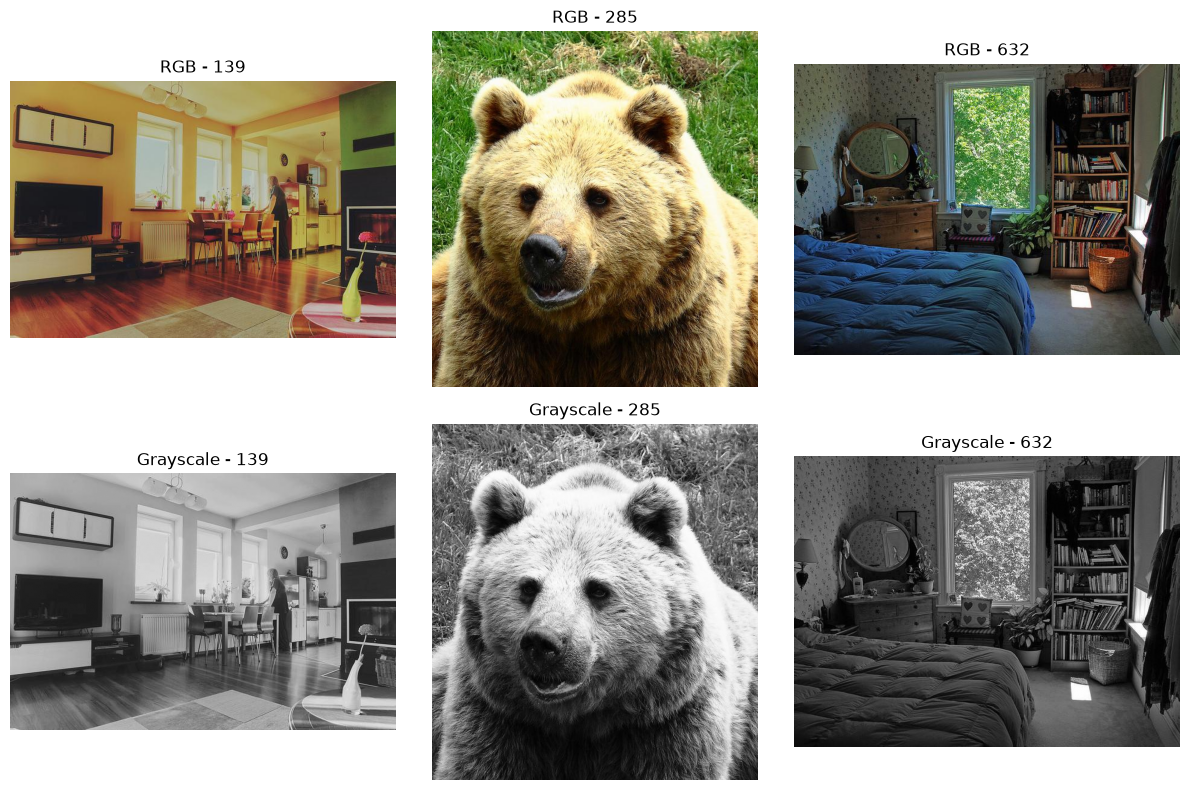

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, image_id in enumerate(testing_image_ids[:3]):

    filename = image_info_by_id[image_id]["filename"]

    rgb_image = Image.open(TEST_RGB_DIR / filename)
    gray_image = Image.open(TEST_GRAY_DIR / filename)

    axes[0, i].imshow(rgb_image)
    axes[0, i].set_title(f"RGB - {image_id}")
    axes[0, i].axis("off")

    axes[1, i].imshow(gray_image, cmap="gray")
    axes[1, i].set_title(f"Grayscale - {image_id}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## 14. Create Testing Metadata

Combine image information, five reference captions, and object annotations into one structured metadata table.

In [26]:
metadata_records = []

for image_id in testing_image_ids:

    image_info = image_info_by_id[image_id]
    captions = testing_captions[image_id]
    objects = objects_by_image[image_id]

    object_categories = sorted({
        obj["category"] for obj in objects
    })

    record = {
        "image_id": image_id,
        "filename": image_info["filename"],
        "width": image_info["width"],
        "height": image_info["height"],
        "rgb_path": image_info["rgb_path"],
        "grayscale_path": str(
            TEST_GRAY_DIR / image_info["filename"]
        ),
        "caption_1": captions[0],
        "caption_2": captions[1],
        "caption_3": captions[2],
        "caption_4": captions[3],
        "caption_5": captions[4],
        "objects_count": len(objects),
        "object_categories": ", ".join(object_categories),
        "object_details": json.dumps(objects)
    }

    metadata_records.append(record)

metadata_df = pd.DataFrame(metadata_records)

display(metadata_df.head())

,image_id,filename,width,height,rgb_path,grayscale_path,caption_1,caption_2,caption_3,caption_4,caption_5,objects_count,object_categories,object_details
0,139,000000000139.jpg,640,426,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,A woman stands in the dining area at the table.,"A room with chairs, a table, and a woman in it.",A woman standing in a kitchen by a window,A person standing at a table in a room.,A living area with a television and a table,20,"book, chair, clock, dining table, microwave, p...","[{""category"": ""potted plant"", ""category_id"": 6..."
1,285,000000000285.jpg,586,640,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,A big burly grizzly bear is show with grass in...,The large brown bear has a black nose.,Closeup of a brown bear sitting in a grassy area.,A large bear that is sitting on grass.,A close up picture of a brown bear's face.,1,bear,"[{""category"": ""bear"", ""category_id"": 23, ""bbox..."
2,632,000000000632.jpg,640,483,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"Bedroom scene with a bookcase, blue comforter ...",A bedroom with a bookshelf full of books.,This room has a bed with blue sheets and a lar...,A bed and a mirror in a small room.,a bed room with a neatly made bed a window and...,18,"bed, book, chair, potted plant","[{""category"": ""bed"", ""category_id"": 65, ""bbox""..."
3,724,000000000724.jpg,375,500,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,A stop sign is mounted upside-down on it's post.,A stop sign that is hanging upside down.,An upside down stop sign by the road.,a stop sign put upside down on a metal pole,A stop sign installed upside down on a street ...,4,"car, stop sign, truck","[{""category"": ""stop sign"", ""category_id"": 13, ..."
4,776,000000000776.jpg,428,640,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"Three teddy bears, each a different color, snu...",Three stuffed animals are sitting on a bed.,three teddy bears giving each other a hug,A group of three stuffed animal teddy bears.,Three stuffed bears hugging and sitting on a b...,4,"bed, teddy bear","[{""category"": ""teddy bear"", ""category_id"": 88,..."


## 15. Verify Testing Dataset

Verify the number of images, unique IDs, reference captions, and processed image files.

In [27]:
print("Number of images:", len(metadata_df))
print("Unique image IDs:", metadata_df["image_id"].nunique())

print("RGB files:", sum(
    Path(path).exists()
    for path in metadata_df["rgb_path"]
))

print("Grayscale files:", sum(
    Path(path).exists()
    for path in metadata_df["grayscale_path"]
))

assert len(metadata_df) == 100
assert metadata_df["image_id"].nunique() == 100

assert all(Path(p).exists() for p in metadata_df["rgb_path"])
assert all(Path(p).exists() for p in metadata_df["grayscale_path"])

print("Testing dataset verified successfully!")

Number of images: 100
Unique image IDs: 100
RGB files: 100
Grayscale files: 100
Testing dataset verified successfully!


## 16. Save Testing Dataset

Save the testing metadata and selected image IDs for future RAG evaluation.

In [28]:
metadata_path = TEST_DATA_DIR / "metadata_testing.csv"

metadata_df.to_csv(
    metadata_path,
    index=False,
    encoding="utf-8-sig"
)

ids_path = TEST_DATA_DIR / "testing_image_ids.json"

with open(ids_path, "w", encoding="utf-8") as file:
    json.dump(testing_image_ids, file, indent=4)

print("Testing metadata saved:", metadata_path)
print("Testing IDs saved:", ids_path)

Testing metadata saved: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\metadata_testing.csv
Testing IDs saved: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\testing_image_ids.json


## 17. Final Testing Dataset Summary

Display the final statistics of the prepared COCO testing dataset.

In [29]:
print("=" * 45)
print("TESTING DATASET SUMMARY")
print("=" * 45)

print("Dataset: COCO 2017 val")
print("Testing images:", len(metadata_df))
print("Reference captions per image: 5")
print("Total reference captions:", len(metadata_df) * 5)

print("RGB images:", len(list(TEST_RGB_DIR.glob("*.jpg"))))
print("Grayscale images:", len(list(TEST_GRAY_DIR.glob("*.jpg"))))

print("Metadata file:", metadata_path)
print("Testing IDs file:", ids_path)

print("\nTesting dataset preparation completed!")

TESTING DATASET SUMMARY
Dataset: COCO 2017 val
Testing images: 100
Reference captions per image: 5
Total reference captions: 500
RGB images: 100
Grayscale images: 100
Metadata file: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\metadata_testing.csv
Testing IDs file: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\testing_image_ids.json

Testing dataset preparation completed!


In [1]:
import json
import shutil
from pathlib import Path
import random

# 1. Paths
new_images_dir = Path("../data/testing_zip_images")
final_test_dir = Path("../data/test/test_subset_100")
splits_file = Path("../data/test/test_ids.json")

# Make sure the final directory is empty before we copy new ones
if final_test_dir.exists():
    shutil.rmtree(final_test_dir)
final_test_dir.mkdir(parents=True, exist_ok=True)

# 2. Get all new images
all_new_images = list(new_images_dir.rglob("*.jpg"))
print(f"Found {len(all_new_images)} images in the new zip.")

# 3. Select exactly 100 images (or all if there are exactly 100)
# (Using random.sample ensures a random mix)
random.seed(42) # Seed ensures reproducibility
selected_images = random.sample(all_new_images, 100) if len(all_new_images) >= 100 else all_new_images

# 4. Extract their IDs (remove .jpg and leading zeros) and update test_ids.json
new_test_ids = []
for img_path in selected_images:
    # Get the filename (e.g., "000000000139.jpg")
    filename = img_path.name
    # Extract the numeric ID (e.g., 139)
    img_id = int(filename.replace(".jpg", ""))
    new_test_ids.append(img_id)
    
    # Copy the image to the final test folder
    shutil.copy(img_path, final_test_dir / filename)

# 5. Save the new test_ids.json
with open(splits_file, "w") as f:
    json.dump(new_test_ids, f)

print(f"✅ Successfully updated test_ids.json and copied 100 images to {final_test_dir}")

# 6. Re-run the Anti-Leakage Audit with the new IDs
with open("../data/train/train_ids.json", "r") as f:
    train_ids = set(json.load(f))

overlap = set(new_test_ids).intersection(train_ids)
print(f"\n--- Anti-Leakage Audit ---")
if len(overlap) == 0:
    print("✅ PASSED: 0 overlapping IDs between the new test set and the training set.")
else:
    print(f"🚨 FAILED: Found {len(overlap)} overlaps with the training set!")

Found 0 images in the new zip.
✅ Successfully updated test_ids.json and copied 100 images to ..\data\test\test_subset_100

--- Anti-Leakage Audit ---
✅ PASSED: 0 overlapping IDs between the new test set and the training set.
